# ARIMA — final aligned evaluation version (v6.1)

This notebook fits a separate univariate ARIMA model for each bank using the approved cleaned dataset and agreed chronological evaluation windows. Stationarity assessment and AIC order selection use training observations only. Forecasts use expanding-window, one-step-ahead evaluation: the actual close is added to the history only after that date's forecast is made.

The notebook includes a persistence benchmark, actual-versus-predicted regression plots with R², and residual diagnostics. Formal training-residual tests exclude state-space likelihood burn-in observations. The out-of-sample forecast residual plot is the report's Figure 9. The old ARIMA metric heatmap is not generated.

Report-facing numerical displays and summary exports use two decimal places. Very small diagnostic p-values are shown as <0.01 rather than 0.00. Full-precision forecast-level values are retained in the reproducibility export.

### Importing Libraries

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from numpy.linalg import LinAlgError

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.25})
# Report-facing display convention; calculations and forecast exports retain full precision.
pd.set_option("display.float_format", lambda value: f"{value:.2f}")


## Load Dataset

In [2]:
# Load the same combined, GBX-standardised dataset used by the other models.
df = pd.read_csv("/content/all_bank_stock_data_clean.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

RESEARCH_START = pd.Timestamp("2015-01-02")
RESEARCH_END = pd.Timestamp("2026-08-24")
df = df.loc[df["Date"].between(RESEARCH_START, RESEARCH_END, inclusive="both")].copy()

if "Close_GBX" not in df.columns:
    raise ValueError(
        "Expected Close_GBX in all_bank_stock_data_clean.csv. "
        "Use the cleaned dataset with Goldman Sachs converted to GBX."
    )

df["Close_GBX"] = pd.to_numeric(df["Close_GBX"], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Date", "Bank", "Close_GBX"])
df = df.sort_values(["Bank", "Date"]).reset_index(drop=True)

print("Research period:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Rows:", len(df))
print("Banks:", sorted(df["Bank"].astype(str).unique()))
df.head()


# Dataset provenance checks: currency is supported by the supplied metadata evidence.
expected_rows = {"Lloyds": 2939, "Barclays": 2936, "Goldman Sachs": 2927}
observed_rows = df.groupby("Bank").size().to_dict()
assert observed_rows == expected_rows, f"Unexpected cleaned row counts: {observed_rows}"
assert df["Date"].min() == RESEARCH_START and df["Date"].max() == RESEARCH_END
assert df[["Bank", "Date"]].duplicated().sum() == 0
assert df["Close_GBX"].notna().all() and np.isfinite(df["Close_GBX"]).all()
print("Validated final cleaned dataset: 8,802 rows; 2,939 Lloyds; 2,936 Barclays; 2,927 Goldman Sachs.")


Research period: 2015-01-02 to 2026-08-24
Rows: 8802
Banks: ['Barclays', 'Goldman Sachs', 'Lloyds']
Validated final cleaned dataset: 8,802 rows; 2,939 Lloyds; 2,936 Barclays; 2,927 Goldman Sachs.


## Dataset overview

The input is `all_bank_stock_data_clean.csv`, produced by the supervisor-approved scraping and cleaning notebook. `Close_GBX` is the modelling target, placing all three closing-price series on a common GBX scale. ARIMA is nevertheless fitted **separately for each bank**; observations are not pooled into one ARIMA model.

## Research period and evaluation dates

The research period is fixed. To make model comparisons meaningful, the training cutoff and each bank's test start date are fixed to the shared evaluation protocol used by the other model notebooks. Any observations between the common training cutoff and a bank's test start date are excluded from that bank's evaluation rather than used to create different test windows.

## Prepare each bank's closing-price series

ARIMA is a univariate model in this study and uses only each bank's `Close_GBX` series. The banks are kept separate, and observations are ordered chronologically.

In [3]:
# Prepare a separate chronological series for each bank.
bank_data = {}
for name, bdf in df.groupby("Bank", sort=True):
    label = str(name)
    series_df = (
        bdf[["Date", "Close_GBX"]]
        .dropna()
        .sort_values("Date")
        .drop_duplicates(subset="Date", keep="last")
        .set_index("Date")
    )
    series_df["Close_GBX"] = pd.to_numeric(series_df["Close_GBX"], errors="coerce")
    series_df = series_df.replace([np.inf, -np.inf], np.nan).dropna()
    if len(series_df) < 100:
        raise ValueError(f"Insufficient observations for {label}: {len(series_df)}")
    bank_data[label] = series_df

    print(f"--- {label} ---")
    print("observations:", len(series_df))
    print("date range:", series_df.index.min().date(), "to", series_df.index.max().date())
    print("missing closing prices:", int(series_df["Close_GBX"].isna().sum()))


--- Barclays ---
observations: 2936
date range: 2015-01-02 to 2026-08-24
missing closing prices: 0
--- Goldman Sachs ---
observations: 2927
date range: 2015-01-02 to 2026-08-24
missing closing prices: 0
--- Lloyds ---
observations: 2939
date range: 2015-01-02 to 2026-08-24
missing closing prices: 0


In [4]:
# Preview the actual columns retained for ARIMA.
# This dataset intentionally contains Date, Bank and Close_GBX for each bank;
# ARIMA is a univariate closing-price model and does not require raw OHLCV columns.
for name, series_df in bank_data.items():
    print(f"--- {name} ---")
    display(series_df[["Close_GBX"]].head(3))


--- Barclays ---


,Close_GBX
Date,
2015-01-02,243.15
2015-01-05,234.70
2015-01-06,230.35


--- Goldman Sachs ---


,Close_GBX
Date,
2015-01-02,12477.43
2015-01-05,12088.79
2015-01-06,12072.69


--- Lloyds ---


,Close_GBX
Date,
2015-01-02,76.15
2015-01-05,74.62
2015-01-06,72.87


## ARIMA Pipeline Functions

In [5]:
def adf_test(series, name=""):
    """ADF stationarity test; caller must pass training data only."""
    clean = pd.Series(series).astype(float).replace([np.inf, -np.inf], np.nan).dropna()
    if len(clean) < 20:
        raise ValueError(f"Not enough training observations for ADF test: {name}")
    result = adfuller(clean, autolag="AIC")
    is_stationary = result[1] <= 0.05
    p_text = "<0.01" if result[1] < 0.01 else f"{result[1]:.2f}"
    print(f"[{name}] ADF statistic={result[0]:.2f}, p-value={p_text}; "
          f"{'stationary' if is_stationary else 'non-stationary'}")
    return is_stationary, result


In [6]:
def plot_training_diagnostics(series, name="Lloyds", lags=40):
    """Plot differenced training series and its ACF/PACF for one representative bank."""
    differenced = series.diff().dropna()
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(differenced.index, differenced.values, linewidth=0.7)
    axes[0].set_title(f"{name}: first-differenced training close")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Daily change (GBX)")
    plot_acf(differenced, lags=lags, ax=axes[1], zero=False)
    axes[1].set_title(f"{name}: ACF of first differences")
    plot_pacf(differenced, lags=lags, ax=axes[2], zero=False, method="ywm")
    axes[2].set_title(f"{name}: PACF of first differences")
    fig.tight_layout()
    plt.show()
    return differenced

In [7]:
def grid_search_arima(train, d=1, p_range=range(4), q_range=range(4), label=''):
    """Select a reasonably compact ARIMA order using training data only.

    The smaller search space avoids unnecessarily high-order specifications
    that can become numerically singular during expanding-window refits.
    """
    best_aic, best_order, best_model = float('inf'), None, None
    for p in p_range:
        for q in q_range:
            try:
                fit = ARIMA(
                    train, order=(p, d, q),
                    enforce_stationarity=False,
                    enforce_invertibility=False
                ).fit()
                if np.isfinite(fit.aic) and fit.aic < best_aic:
                    best_aic, best_order, best_model = fit.aic, (p, d, q), fit
            except (Exception):
                continue
    print(f"[{label}] Best order: {best_order}   AIC: {best_aic:.2f}")
    return best_model, best_order, best_aic


In [8]:
def forecast_arima(train, test, order, label=""):
    """Expanding-window one-step forecasts with numerical-stability fallbacks.

    The selected order is attempted first at each forecast origin. If a
    state-space LU decomposition or convergence failure occurs, progressively
    simpler ARIMA specifications are tried on the same available history.
    The observed test value is appended only after that date's forecast.
    """
    history = list(np.asarray(train, dtype=float))
    predictions = []
    fallback_counts = {}

    p, d, q = order
    candidates = [
        order,
        (min(p, 2), d, min(q, 2)),
        (1, d, 0),
        (0, d, 1),
        (0, d, 0),
    ]
    # Preserve order while removing duplicate candidates.
    candidates = list(dict.fromkeys(candidates))

    for step, actual_value in enumerate(np.asarray(test, dtype=float)):
        yhat = None
        last_error = None
        for candidate in candidates:
            try:
                fitted = ARIMA(
                    history, order=candidate,
                    enforce_stationarity=False,
                    enforce_invertibility=False
                ).fit()
                candidate_forecast = float(
                    np.asarray(fitted.forecast(steps=1)).reshape(-1)[0]
                )
                if np.isfinite(candidate_forecast):
                    yhat = candidate_forecast
                    fallback_counts[candidate] = fallback_counts.get(candidate, 0) + 1
                    break
                last_error = ValueError("Non-finite forecast")
            except Exception as exc:
                last_error = exc

        if yhat is None:
            raise RuntimeError(
                f"All ARIMA specifications failed for {label} at test step "
                f"{step}. Last error: {type(last_error).__name__}: {last_error}"
            )

        predictions.append(yhat)
        history.append(float(actual_value))

    print(f"[{label}] walk-forward complete: {len(predictions)} one-step forecasts")
    print(f"[{label}] fitted-order usage: {fallback_counts}")
    return pd.Series(predictions, index=test.index, name="ARIMA_Forecast")


In [9]:
def evaluate_forecast(test, forecast):
    actual = np.asarray(test, dtype=float).reshape(-1)
    predicted = np.asarray(forecast, dtype=float).reshape(-1)
    if actual.shape != predicted.shape:
        raise ValueError(f"Actual/forecast length mismatch: {actual.shape} vs {predicted.shape}")
    if not (np.isfinite(actual).all() and np.isfinite(predicted).all()):
        raise ValueError("ARIMA evaluation received NaN or infinite values.")

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = np.abs(actual) > 1e-12
    mape = (
        np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )
    r2 = r2_score(actual, predicted) if len(actual) >= 2 else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2}


def directional_accuracy(actual, predicted, previous_actual):
    """Compare forecasted and realised price changes from the same prior actual close.

    The first test forecast uses the final training close as its reference. For
    subsequent dates, the reference is the immediately preceding actual test close.
    Zero changes are treated as a separate direction category for both series.
    """
    actual = pd.Series(actual, dtype=float)
    predicted = pd.Series(predicted, index=actual.index, dtype=float)
    previous_actual = pd.Series(previous_actual, index=actual.index, dtype=float)
    actual_change = actual - previous_actual
    predicted_change = predicted - previous_actual
    valid = actual_change.notna() & predicted_change.notna()
    if not valid.any():
        return np.nan
    return float((np.sign(actual_change[valid]) == np.sign(predicted_change[valid])).mean() * 100)


def previous_actual_values(train, test):
    """Previous observed close for every test date, including the train/test boundary."""
    previous = np.concatenate(([float(train.iloc[-1])], test.to_numpy(dtype=float)[:-1]))
    return pd.Series(previous, index=test.index, name="Previous_Actual_Close")

In [10]:
def plot_actual_vs_forecast(results):
    """One compact time-series figure with one panel per bank."""
    fig, axes = plt.subplots(len(results), 1, figsize=(13, 9), sharex=False)
    if len(results) == 1:
        axes = [axes]
    for ax, (name, r) in zip(axes, results.items()):
        ax.plot(r["test"].index, r["test"].values, label="Actual", linewidth=1.0)
        ax.plot(r["forecast"].index, r["forecast"].values, label="ARIMA forecast", linewidth=1.0)
        ax.set_title(name)
        ax.set_ylabel("Close (GBX)")
        ax.legend()
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[-1].set_xlabel("Date")
    fig.suptitle("One-step-ahead ARIMA forecasts on the common evaluation period", y=1.01)
    fig.tight_layout()
    plt.show()


def plot_best_fit(results):
    """Scatter actual vs predicted with identity and fitted regression lines."""
    fig, axes = plt.subplots(1, len(results), figsize=(15, 4.8))
    if len(results) == 1:
        axes = [axes]
    for ax, (name, r) in zip(axes, results.items()):
        actual = r["test"].to_numpy(dtype=float)
        predicted = r["forecast"].to_numpy(dtype=float)
        ax.scatter(actual, predicted, s=9, alpha=0.35)
        low = float(min(actual.min(), predicted.min()))
        high = float(max(actual.max(), predicted.max()))
        ax.plot([low, high], [low, high], linestyle="--", linewidth=1.2, label="Ideal: y = x")
        slope, intercept = np.polyfit(actual, predicted, 1)
        xline = np.linspace(low, high, 100)
        ax.plot(xline, slope * xline + intercept, linewidth=1.5, label="Fitted regression")
        ax.set_title(f"{name}\nR² = {r['R2']:.2f}")
        ax.set_xlabel("Actual close (GBX)")
        ax.set_ylabel("Predicted close (GBX)")
        ax.legend(fontsize=8)
    fig.suptitle("Actual versus predicted closing prices: fit and R²", y=1.03)
    fig.tight_layout()
    plt.show()


def plot_residual_diagnostics(residuals, name="Lloyds"):
    """A concise residual histogram and ACF for the representative bank."""
    residuals = pd.Series(residuals).dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(residuals, bins=40, edgecolor="black", linewidth=0.3)
    axes[0].set_title(f"{name}: ARIMA training residual distribution")
    axes[0].set_xlabel("Residual (GBX)")
    axes[0].set_ylabel("Frequency")
    plot_acf(residuals, lags=min(30, max(5, len(residuals)//3)), ax=axes[1], zero=False)
    axes[1].set_title(f"{name}: residual autocorrelation")
    fig.tight_layout()
    plt.show()


def plot_out_of_sample_residuals(results):
    """Plot one-step-ahead test errors over time for all banks, with a zero reference."""
    fig, axes = plt.subplots(len(results), 1, figsize=(13, 8), sharex=False)
    if len(results) == 1:
        axes = [axes]
    for ax, (name, r) in zip(axes, results.items()):
        errors = r["test"] - r["forecast"]
        ax.plot(errors.index, errors.values, linewidth=0.8)
        ax.axhline(0, linestyle="--", linewidth=1.0)
        ax.set_title(f"{name}: out-of-sample forecast residuals")
        ax.set_ylabel("Error (GBX)")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[-1].set_xlabel("Date")
    fig.suptitle("One-step-ahead ARIMA forecast residuals", y=1.01)
    fig.tight_layout()
    plt.show()


## Run the Pipeline for All Three Banks

Barclays
Training: 2347 rows | 2015-01-02 to 2024-04-22
Testing:  587 rows | 2024-04-25 to 2026-08-24
Excluded transition-gap dates: 2
[Barclays training level] ADF statistic=-2.53, p-value=0.11; non-stationary
[Barclays training first difference] ADF statistic=-47.56, p-value=<0.01; stationary
[Barclays training only] Best order: (3, 1, 3)   AIC: 12559.64
[Barclays] walk-forward complete: 587 one-step forecasts
[Barclays] fitted-order usage: {(3, 1, 3): 587}
Selected ARIMA(3, 1, 3) | MAE=5.07 GBX | RMSE=6.90 GBX | MAPE=1.47% | R²=1.00
Goldman Sachs
Training: 2341 rows | 2015-01-02 to 2024-04-22
Testing:  586 rows | 2024-04-23 to 2026-08-24
Excluded transition-gap dates: 0
[Goldman Sachs training level] ADF statistic=-0.50, p-value=0.89; non-stationary
[Goldman Sachs training first difference] ADF statistic=-10.15, p-value=<0.01; stationary
[Goldman Sachs training only] Best order: (0, 1, 3)   AIC: 34193.67
[Goldman Sachs] walk-forward complete: 586 one-step forecasts
[Goldman Sachs] f

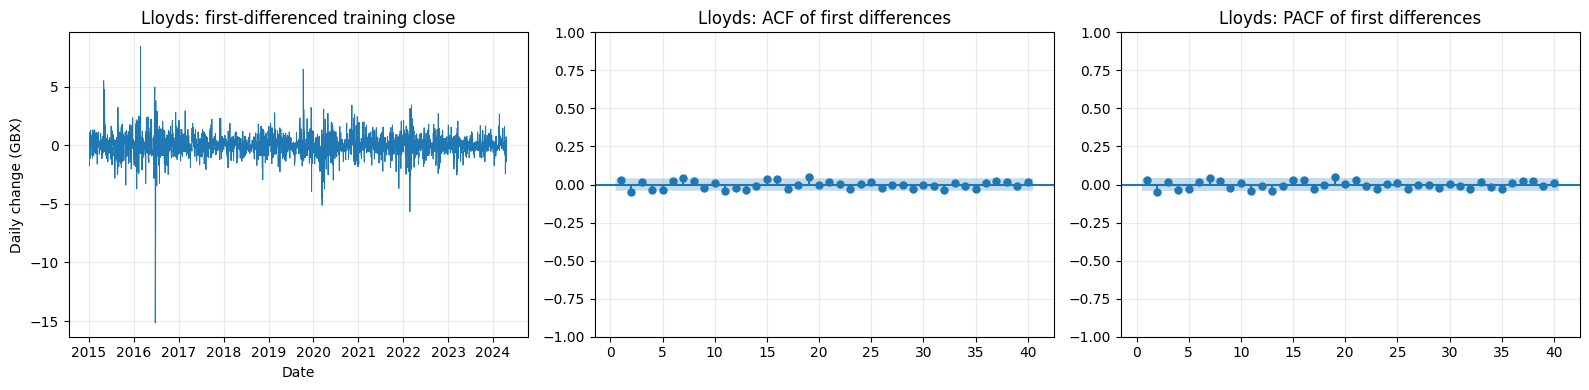

In [11]:
# Fixed evaluation dates shared with the other model notebooks.
COMMON_TRAIN_END = pd.Timestamp("2024-04-22")
TEST_START_DATES = {
    "Barclays": pd.Timestamp("2024-04-25"),
    "Goldman Sachs": pd.Timestamp("2024-04-23"),
    "Lloyds": pd.Timestamp("2024-04-26"),
}

results = {}
training_diagnostic_series = {}

for name, bdf in bank_data.items():
    if name not in TEST_START_DATES:
        raise ValueError(f"No agreed test start date configured for {name}.")

    series = bdf["Close_GBX"].astype(float).sort_index()
    train = series.loc[series.index <= COMMON_TRAIN_END]
    test = series.loc[series.index >= TEST_START_DATES[name]]

    if train.empty or test.empty:
        raise ValueError(f"Empty train/test split for {name}. Check the cleaned input dates.")
    if train.index.max() >= test.index.min():
        raise ValueError(f"Training/test overlap for {name}.")
    if test.index.max() > RESEARCH_END:
        raise ValueError(f"Test period exceeds the agreed research end date for {name}.")

    print("=" * 72)
    print(name)
    print(f"Training: {len(train)} rows | {train.index.min().date()} to {train.index.max().date()}")
    print(f"Testing:  {len(test)} rows | {test.index.min().date()} to {test.index.max().date()}")
    print(f"Excluded transition-gap dates: {int(((series.index > COMMON_TRAIN_END) & (series.index < TEST_START_DATES[name])).sum())}")

    # ADF test and AIC order selection use training data only.
    stationary, adf_level = adf_test(train, name=f"{name} training level")
    d = 0 if stationary else 1
    if d == 1:
        adf_test(train.diff().dropna(), name=f"{name} training first difference")

    best_model, best_order, best_aic = grid_search_arima(
        train, d=d, p_range=range(4), q_range=range(4), label=f"{name} training only"
    )
    if best_order is None:
        raise RuntimeError(f"ARIMA order search failed for {name}.")

    forecast = forecast_arima(train, test, best_order, label=name)
    metrics = evaluate_forecast(test, forecast)

    # Directional accuracy is calculated once, alongside the persistence baseline,
    # using the shared previous-actual reference for both forecasting methods.
    directional_accuracy_value = np.nan

    results[name] = {
        "Bank": name,
        "Order": best_order,
        "AIC": best_aic,
        "Train_Start": train.index.min().date().isoformat(),
        "Train_End": train.index.max().date().isoformat(),
        "Test_Start": test.index.min().date().isoformat(),
        "Test_End": test.index.max().date().isoformat(),
        "Train_N": len(train),
        "Test_N": len(test),
        **metrics,
        "Directional_Accuracy": directional_accuracy_value,
        "model": best_model,
        "forecast": forecast,
        "test": test,
        "train": train,
    }

    print(
        f"Selected ARIMA{best_order} | MAE={metrics['MAE']:.2f} GBX | "
        f"RMSE={metrics['RMSE']:.2f} GBX | MAPE={metrics['MAPE']:.2f}% | "
        f"R²={metrics['R2']:.2f}"
    )

# Training differencing / ACF / PACF are shown once for Lloyds as a representative series.
if "Lloyds" in results:
    training_diagnostic_series["Lloyds"] = plot_training_diagnostics(
        results["Lloyds"]["train"], name="Lloyds", lags=40
    )

## Forecast visualisation

The following figure shows the actual and one-step-ahead forecast series for each bank. This is the main time-series forecast plot; separate duplicate plots for each bank are not generated.

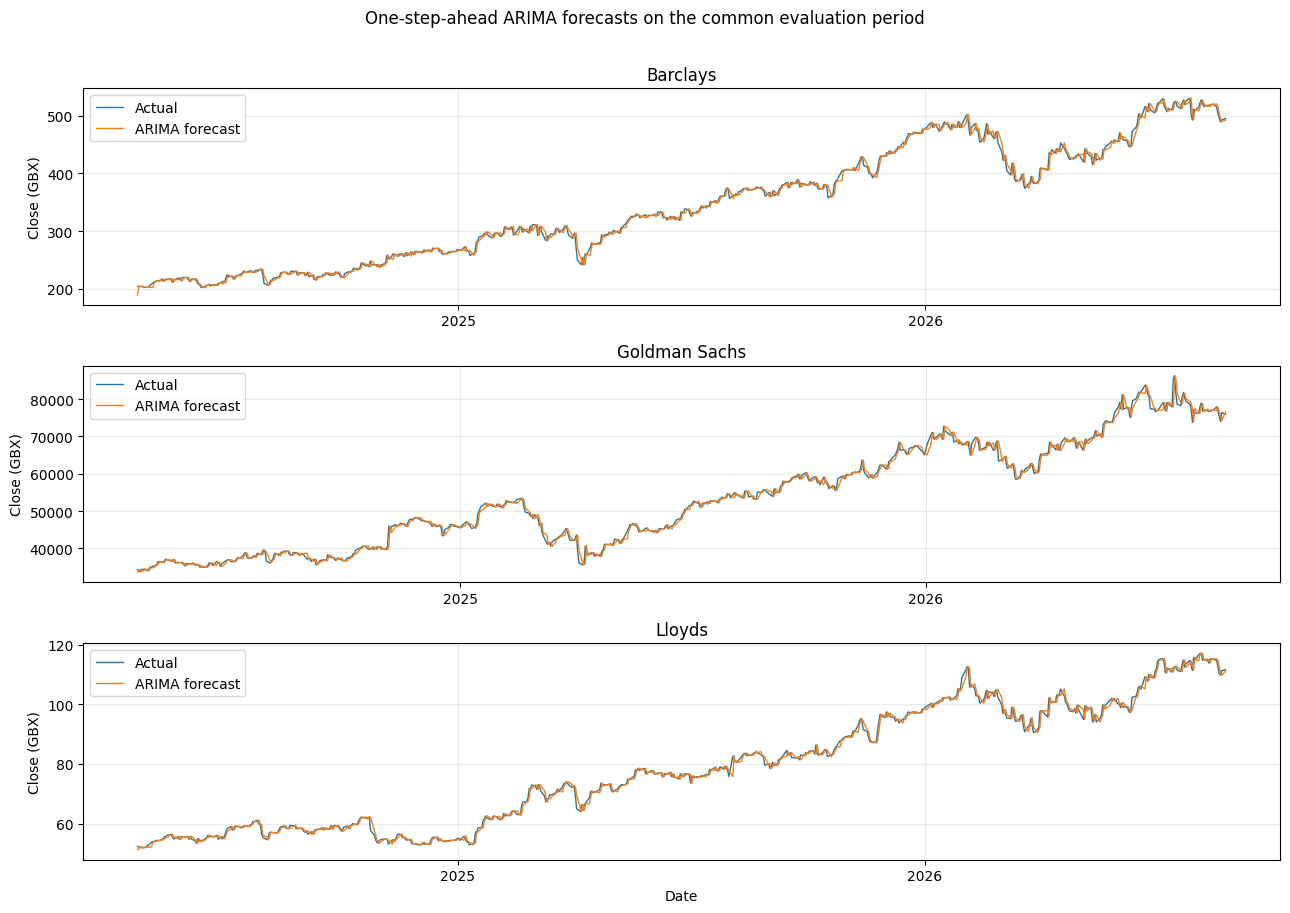

In [12]:
plot_actual_vs_forecast(results)

## Model summaries

The selected ARIMA order and AIC are reported for transparency. Full model summaries can be inspected below if coefficient-level detail is required; they are not repeated as separate figures.

## Persistence baseline

The persistence baseline predicts the next closing price as the most recent observed closing price. It is evaluated over exactly the same dates as ARIMA. This is essential because high price-level R² can arise from the persistence of stock prices.

In [13]:
def evaluate_persistence(train, test):
    """One-step persistence forecast: next close equals the latest observed close."""
    previous = float(train.iloc[-1])
    predictions = []
    for actual_value in test.to_numpy(dtype=float):
        predictions.append(previous)
        previous = float(actual_value)
    forecast = pd.Series(predictions, index=test.index, name="Persistence_Forecast")
    return forecast, evaluate_forecast(test, forecast)


persistence_results = {}
for name, r in results.items():
    p_forecast, p_metrics = evaluate_persistence(r["train"], r["test"])
    previous_actual = previous_actual_values(r["train"], r["test"])

    # Both methods are scored against the same actual daily movement.
    arima_direction = directional_accuracy(r["test"], r["forecast"], previous_actual)
    # Persistence predicts no price movement. Directional accuracy is therefore
    # not applicable: scoring a zero-change prediction against up/down moves
    # would reward only unchanged prices and would not be comparable with ARIMA.
    r["Directional_Accuracy"] = arima_direction

    persistence_results[name] = {
        **p_metrics,
        "Directional_Accuracy": np.nan,
        "forecast": p_forecast,
    }

    print(
        f"{name}: ARIMA MAE={r['MAE']:.2f} GBX; Persistence MAE={p_metrics['MAE']:.2f} GBX; "
        f"ARIMA direction={arima_direction:.2f}%; Persistence direction=N/A (no directional prediction)"
    )

Barclays: ARIMA MAE=5.07 GBX; Persistence MAE=5.05 GBX; ARIMA direction=47.70%; Persistence direction=N/A (no directional prediction)
Goldman Sachs: ARIMA MAE=785.69 GBX; Persistence MAE=785.84 GBX; ARIMA direction=52.90%; Persistence direction=N/A (no directional prediction)
Lloyds: ARIMA MAE=0.97 GBX; Persistence MAE=0.96 GBX; ARIMA direction=44.90%; Persistence direction=N/A (no directional prediction)


## Residual diagnostics

Two residual concepts are kept distinct. **Training residuals** are taken from each selected ARIMA fit. Before formal testing, the notebook excludes the model's state-space likelihood burn-in observations, which can be affected by initialisation. The Ljung–Box test assesses remaining autocorrelation, Jarque–Bera assesses normality, and ARCH-LM assesses conditional heteroskedasticity. The histogram and ACF are shown once for Lloyds to avoid repetitive plots.

**Out-of-sample forecast residuals** are defined as actual close minus one-step-ahead forecast. Figure 9 plots these errors over time for all three banks, with a zero reference line. Residuals fluctuating around zero without systematic patterns are desirable; trends, changing spread or clusters suggest forecast errors are not random.

Formal tests use post-burn-in training residuals, not the out-of-sample forecast errors shown in Figure 9. The Ljung–Box degrees of freedom are adjusted for the fitted AR and MA terms (p + q).

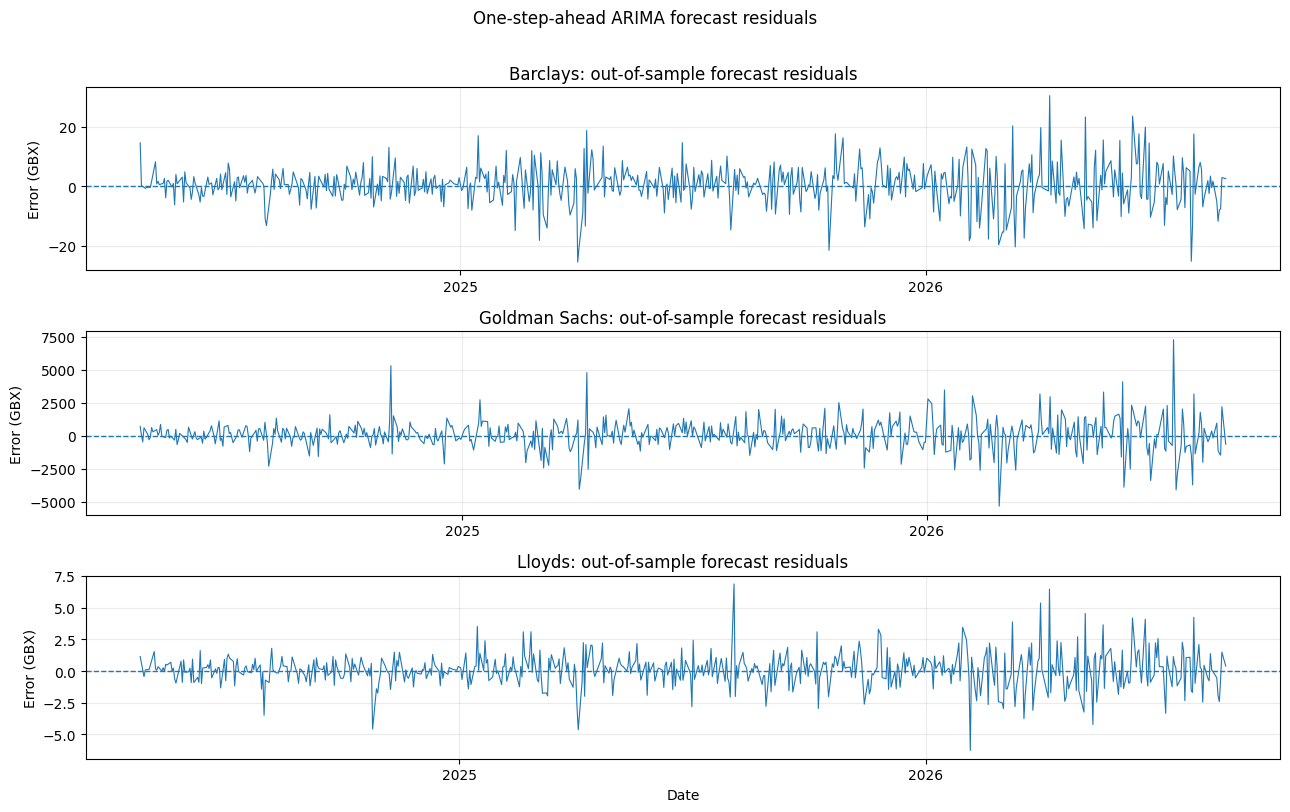

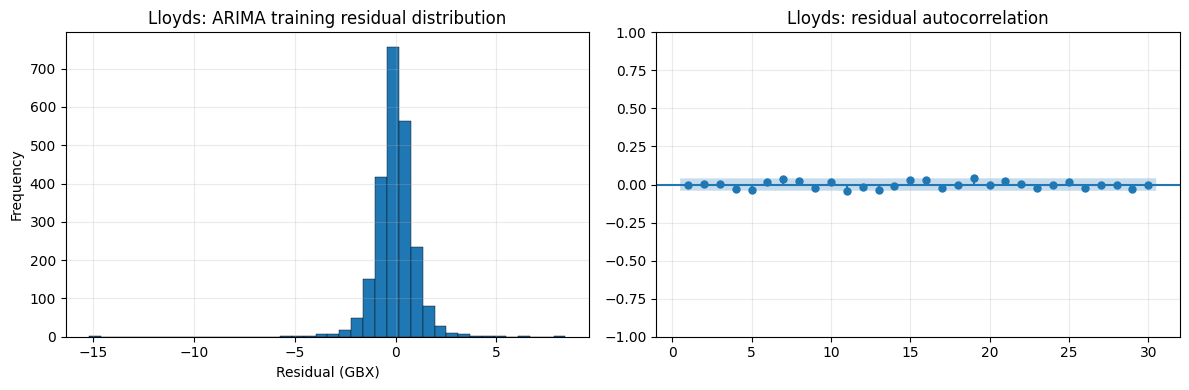

Training-residual diagnostics after likelihood burn-in:


,Bank,ARIMA_Order,Likelihood_Burn_In_Excluded,Residual_N_After_Burn_In,Ljung_Box_lag,Ljung_Box_model_df,Ljung_Box_p,Jarque_Bera_p,Residual_skew,Residual_kurtosis,ARCH_LM_lag,ARCH_LM_p
0,Barclays,"(3, 1, 3)",5,2342,10,6,0.17,<0.01,-0.68,9.47,10,<0.01
1,Goldman Sachs,"(0, 1, 3)",5,2336,10,3,0.02,<0.01,-0.06,6.31,10,<0.01
2,Lloyds,"(0, 1, 3)",5,2343,10,3,0.07,<0.01,-1.20,31.19,10,<0.01


In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

# Figure 9: out-of-sample forecast residuals (actual close minus forecast).
plot_out_of_sample_residuals(results)

diagnostic_rows = []
residuals_after_burn = {}

for name, r in results.items():
    raw_resid = np.asarray(r["model"].resid, dtype=float).reshape(-1)
    burn = int(getattr(r["model"], "loglikelihood_burn", 0) or 0)
    resid = pd.Series(raw_resid[burn:]).replace(
        [np.inf, -np.inf], np.nan
    ).dropna().reset_index(drop=True)

    if len(resid) < 30:
        raise ValueError(f"Too few post-burn-in training residuals for diagnostics: {name}")

    p, d, q = r["Order"]
    lb_lag = min(10, max(1, len(resid) // 5))
    model_df = p + q
    lb = acorr_ljungbox(resid, lags=[lb_lag], model_df=model_df, return_df=True)
    lb_p = float(lb["lb_pvalue"].iloc[-1])

    jb_stat, jb_pvalue, skew, kurtosis = jarque_bera(resid)
    arch_lag = min(10, max(1, len(resid) // 5))
    arch_stat, arch_pvalue, _, _ = het_arch(resid, nlags=arch_lag)

    diagnostic_rows.append({
        "Bank": name,
        "ARIMA_Order": str(r["Order"]),
        "Likelihood_Burn_In_Excluded": burn,
        "Residual_N_After_Burn_In": int(len(resid)),
        "Ljung_Box_lag": lb_lag,
        "Ljung_Box_model_df": model_df,
        "Ljung_Box_p": lb_p,
        "Jarque_Bera_p": float(jb_pvalue),
        "Residual_skew": float(skew),
        "Residual_kurtosis": float(kurtosis),
        "ARCH_LM_lag": arch_lag,
        "ARCH_LM_p": float(arch_pvalue),
    })
    residuals_after_burn[name] = resid

    if name == "Lloyds":
        plot_residual_diagnostics(resid, name=name)

diagnostics_df = pd.DataFrame(diagnostic_rows)

def format_p_value(value):
    value = float(value)
    return "<0.01" if value < 0.01 else f"{value:.2f}"

diagnostics_display = diagnostics_df.copy()
for p_col in ["Ljung_Box_p", "Jarque_Bera_p", "ARCH_LM_p"]:
    diagnostics_display[p_col] = diagnostics_display[p_col].map(format_p_value)

print("Training-residual diagnostics after likelihood burn-in:")
display(diagnostics_display)

## Actual versus predicted: best-fit plots

The scatter plots show predicted closing prices against actual closing prices. The dashed diagonal is the ideal prediction line (y = x); the solid line is a fitted linear regression line. These plots support interpretation of R² but do not replace error metrics or the persistence comparison.

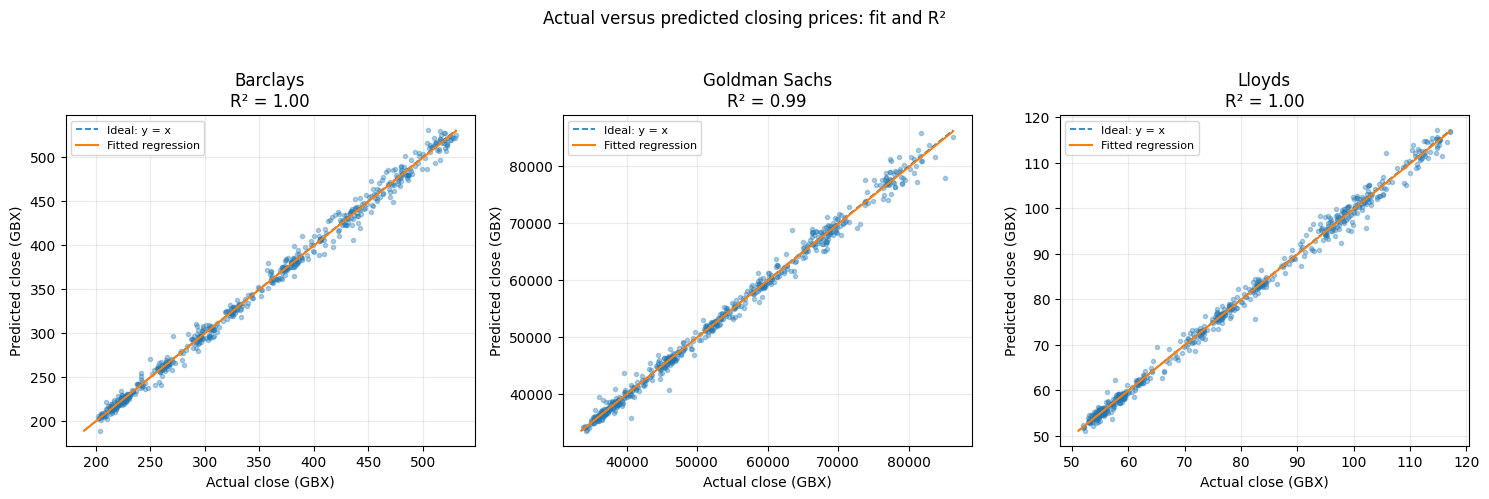

In [15]:
plot_best_fit(results)

## Results tables and exports

MAE and RMSE are reported in GBX. Since the banks have different price levels, absolute GBX errors should be interpreted within each bank rather than used alone to rank banks. MAPE expresses error as a percentage; R² describes variation explained in the test closing-price levels and is accompanied by the actual-versus-predicted regression plots. Directional accuracy measures whether the predicted daily price movement has the same sign as the realised movement.

All displayed summary values and summary CSV exports are rounded to two decimal places. The forecast-level CSV retains full precision so that the analysis remains reproducible.

In [16]:
arima_rows = []
for name, r in results.items():
    arima_rows.append({
        "Bank": name, "Model": "ARIMA", "Order": str(r["Order"]),
        "Train_Start": r["Train_Start"], "Train_End": r["Train_End"],
        "Test_Start": r["Test_Start"], "Test_End": r["Test_End"],
        "Train_N": r["Train_N"], "Test_N": r["Test_N"],
        "MAE_GBX": r["MAE"], "RMSE_GBX": r["RMSE"], "MAPE_pct": r["MAPE"],
        "R2": r["R2"], "Directional_Accuracy_pct": r["Directional_Accuracy"],
        "AIC": r["AIC"]
    })

arima_summary = pd.DataFrame(arima_rows)
persistence_rows = []
for name, r in persistence_results.items():
    persistence_rows.append({
        "Bank": name, "Model": "Persistence",
        "MAE_GBX": r["MAE"], "RMSE_GBX": r["RMSE"], "MAPE_pct": r["MAPE"],
        "R2": r["R2"], "Directional_Accuracy_pct": r["Directional_Accuracy"]
    })
persistence_summary = pd.DataFrame(persistence_rows)

comparison = arima_summary.merge(persistence_summary, on="Bank", suffixes=("_ARIMA", "_Persistence"))

# Round numeric summary fields for report-facing summary exports to 2 decimals.
# Raw model objects and forecast-level data retain full computational precision.
def round_numeric_columns(frame, decimals=2):
    rounded = frame.copy()
    numeric_cols = rounded.select_dtypes(include=[np.number]).columns
    rounded[numeric_cols] = rounded[numeric_cols].round(decimals)
    return rounded

arima_summary_2dp = round_numeric_columns(arima_summary)
persistence_summary_2dp = round_numeric_columns(persistence_summary)
comparison_2dp = round_numeric_columns(comparison)
diagnostics_2dp = round_numeric_columns(diagnostics_df)

display(comparison_2dp)
print("Training residual diagnostic tests:")
display(diagnostics_2dp)

arima_summary_2dp.to_csv("arima_results_summary.csv", index=False)
persistence_summary_2dp.to_csv("arima_persistence_summary.csv", index=False)
diagnostics_export = diagnostics_2dp.copy()
for p_col in ["Ljung_Box_p", "Jarque_Bera_p", "ARCH_LM_p"]:
    diagnostics_export[p_col] = diagnostics_export[p_col].map(format_p_value)
diagnostics_export.to_csv("arima_residual_diagnostics.csv", index=False)
print("Saved report-ready summary files: arima_results_summary.csv, arima_persistence_summary.csv, arima_residual_diagnostics.csv")

,Bank,Model_ARIMA,Order,Train_Start,Train_End,Test_Start,Test_End,Train_N,Test_N,MAE_GBX_ARIMA,...,MAPE_pct_ARIMA,R2_ARIMA,Directional_Accuracy_pct_ARIMA,AIC,Model_Persistence,MAE_GBX_Persistence,RMSE_GBX_Persistence,MAPE_pct_Persistence,R2_Persistence,Directional_Accuracy_pct_Persistence
0,Barclays,ARIMA,"(3, 1, 3)",2015-01-02,2024-04-22,2024-04-25,2026-08-24,2347,587,5.07,...,1.47,1.00,47.70,12559.64,Persistence,5.05,6.89,1.47,1.00,NaN
1,Goldman Sachs,ARIMA,"(0, 1, 3)",2015-01-02,2024-04-22,2024-04-23,2026-08-24,2341,586,785.69,...,1.44,0.99,52.90,34193.67,Persistence,785.84,1141.76,1.44,0.99,NaN
2,Lloyds,ARIMA,"(0, 1, 3)",2015-01-02,2024-04-22,2024-04-26,2026-08-24,2348,588,0.97,...,1.21,1.00,44.90,6628.36,Persistence,0.96,1.36,1.21,1.00,NaN


Training residual diagnostic tests:


,Bank,ARIMA_Order,Likelihood_Burn_In_Excluded,Residual_N_After_Burn_In,Ljung_Box_lag,Ljung_Box_model_df,Ljung_Box_p,Jarque_Bera_p,Residual_skew,Residual_kurtosis,ARCH_LM_lag,ARCH_LM_p
0,Barclays,"(3, 1, 3)",5,2342,10,6,0.17,0.00,-0.68,9.47,10,0.00
1,Goldman Sachs,"(0, 1, 3)",5,2336,10,3,0.02,0.00,-0.06,6.31,10,0.00
2,Lloyds,"(0, 1, 3)",5,2343,10,3,0.07,0.00,-1.20,31.19,10,0.00


Saved report-ready summary files: arima_results_summary.csv, arima_persistence_summary.csv, arima_residual_diagnostics.csv


## Export forecasts for reproducibility

The forecast file retains each bank's actual close, ARIMA forecast and persistence forecast on each test date.

In [17]:
forecast_frames = []
for name, r in results.items():
    forecast_frames.append(pd.DataFrame({
        "Date": r["test"].index,
        "Bank": name,
        "Actual_Close_GBX": r["test"].to_numpy(dtype=float),
        "ARIMA_Forecast_GBX": r["forecast"].to_numpy(dtype=float),
        "Persistence_Forecast_GBX": persistence_results[name]["forecast"].to_numpy(dtype=float),
        "ARIMA_Error_GBX": r["test"].to_numpy(dtype=float) - r["forecast"].to_numpy(dtype=float),
    }))
forecast_output = pd.concat(forecast_frames, ignore_index=True)
forecast_output.to_csv("arima_forecasts_by_bank.csv", index=False)
print("Saved arima_forecasts_by_bank.csv")
display(forecast_output.head())

Saved arima_forecasts_by_bank.csv


,Date,Bank,Actual_Close_GBX,ARIMA_Forecast_GBX,Persistence_Forecast_GBX,ARIMA_Error_GBX
0,2024-04-25,Barclays,204.00,189.39,189.18,14.61
1,2024-04-26,Barclays,204.35,204.09,204.00,0.26
2,2024-04-29,Barclays,203.65,204.37,204.35,-0.72
3,2024-04-30,Barclays,202.70,203.10,203.65,-0.40
4,2024-05-03,Barclays,202.35,202.71,202.70,-0.36


## Interpretation notes

- A high R² on closing-price levels does not by itself demonstrate useful forecasting skill; compare ARIMA with the persistence baseline on the same bank and test dates.
- Directional accuracy is calculated for ARIMA using the previous actual closing price as the reference. The first test date uses the final training close; subsequent test dates use the immediately preceding actual test close.
- Persistence predicts exactly the previous actual close. It therefore predicts zero movement and has **no meaningful directional forecast**; its directional accuracy is reported as N/A, not as the proportion of unchanged prices.
- MAE and RMSE are in GBX; MAPE and directional accuracy are percentages; R² is unitless. Absolute GBX errors should be compared within each bank, not pooled across banks with very different price levels.
- The actual-versus-predicted scatter plots include the identity line, fitted regression line and R². Interpret R² alongside MAE, RMSE, MAPE and persistence rather than as a standalone measure of predictive skill.
- The Ljung–Box test assesses remaining residual autocorrelation; Jarque–Bera assesses residual normality; ARCH-LM assesses conditional heteroskedasticity. Small p-values indicate evidence against the relevant null hypothesis and are displayed as <0.01 where appropriate.
- Formal residual tests use training residuals after excluding the model's likelihood burn-in. Figure 9 uses out-of-sample errors (actual minus forecast); these are different diagnostic quantities and should not be conflated.
- A small p-value does not automatically invalidate point forecasts, but it indicates that some classical residual assumptions are not fully met and should be acknowledged when discussing model limitations and forecast uncertainty.
- Lloyds is used for the representative training-residual histogram and ACF only; numerical diagnostic tests are reported separately for all three banks.
- The notebook does not generate separate metric bar charts or a performance heatmap because these duplicate the tables and can encourage misleading cross-bank comparisons of GBX error magnitudes.
- In the report, explain each figure in the surrounding text. Update the figure list so Figure 9 is the out-of-sample residual plot and remove references to the retired ARIMA metric heatmap.